# 🔥 PyTorch tutorial: **Fully-Connected (Dense) Neural Networks** 

## Table of Contents
- [Theory](#theory)
    - [Fully-connected Neural Networks](#fc_l)
    - [Activation Functions](#act)
    - [Optimizers](#opts)
    - [Losses](#loss)
    - [Training Flow](#clsf)
- [Python](#python)
- [PyTorch](#torch)
- [Bulding and Training NNs](#btnn)
    - [The XOR problem](#xor)
    - [Network Intrusion Detection (NSL-KDD)](#nids)
        - [Data & Preprocessing](#nids_data)
        - [Model & Training](#nids_train)
        - [Optimization Principles](#nids_opt)
        - [Evaluation under Distribution Shift](#nids_eval)
        - [Latent Space Visualization](#nids_latent)
        - [Explainability](#nids_xai)
- [Homework](#hw)

## 📚 **Theory** <a class="anchor" id="theory"></a>

### **Fully-connected Neural Networks** <a class="anchor" id="fc_l"></a>

A **fully-connected neural network**, also known as a **dense neural network** is a fundamental type of artificial neural network. It is composed of layers of interconnected nodes, where each node in one layer is connected to every node in the next layer. The basic building block of a fully-connected neural network is the **fully-connected layer**.

#### **Fully-Connected Layer**

A fully-connected layer can be viewed as a function $f: \mathbb{R}^{N_{\text{in}}} \rightarrow \mathbb{R}^{N_{\text{out}}}$ parametrized by a matrix $ \mathbf{W} \in \mathbb{R}^{N_{\text{out}} \times N_{\text{in}}}$ and vector $ b \in \mathbb{R}^{N_{\text{out}}}$.

Mathematically, the output $ y \in \mathbb{R}^{N_{\text{out}}}$ of a fully-connected layer, given input vector $x \in \mathbb{R}^{N_{\text{in}}}$, can be expressed as: 

$$ y = f(x) = \mathbf{W}x + b $$

<div style="text-align: center;">
  <img src="imgs/fcl.png" alt="description" width="600"/>
  <figcaption>Diagram of a fully-connected layer</figcaption>
</div>

The weight matrix ($ \mathbf{W} $) encapsulates the connections between neurons in the current layer and the next layer. Each element $ w_{ij} $ in ($ \mathbf{W} $) corresponds to the weight of the connection between the $j^{th}$ neuron in the current layer and the $i^{th}$ neuron in the next layer.

The bias vector ( $b$ ) is added to the weighted sum to introduce an offset, allowing the model to learn translations, while also helping in handling non-zero inputs and enhancing expressiveness.

#### *Are such structures still relevant?*

**Yep.**

They are part of current LLM/multimodal architectures:

<div style="text-align: center;">
  <img src="imgs/gpt_linear.png" alt="description" width="800"/>
  <figcaption>Original Architecture of GPT.</figcaption>
</div>

<div style="text-align: center;">
  <img src="imgs/blip.png" alt="description" width="800"/>
  <figcaption>Architecture of <a href="https://arxiv.org/pdf/2301.12597">BLIP-2</a>, for vision-to-language applications.</figcaption>
</div>

### **Activation Functions** <a class="anchor" id="act"></a>

Activation functions play a crucial role in neural networks by introducing non-linearities to the model. These non-linearities enable neural networks to learn and represent complex relationships in data.

Some common activation functions:

- **Sigmoid (Logistic) Function**: $$ \sigma(x) = {{1} \over {1 + e^{-x}}}, \,\, \sigma: \mathbb{R} \rightarrow \mathbb [0, 1] $$ Commonly used in the output layer of binary classification models. Vanishing gradient problems in deep networks.

- **Hyperbolic Tangent (tanh)**: $$ \sigma(x) = {{e^x - e^{-x}} \over {e^x + e^{-x}}}, \,\, \sigma: \mathbb{R} \rightarrow \mathbb [-1, 1] $$ Outputs values in the range (-1, 1). Similar to the sigmoid but with a symmetric range. May help mitigate issues related to vanishing gradients.

- **Rectified Linear Unit (ReLU)**: $$ \sigma(x) = \max(0, x), \,\, \sigma: \mathbb{R} \rightarrow \mathbb [0, \infty] $$ Addresses the vanishing gradient problem compared to traditional sigmoid and tanh. Widely used due to its simplicity, effectiveness and computational efficiency, along with its other variants: Leaky ReLU, PReLU, ELU, etc.

- **Softmax**: for a vector $z = (z_1, \dots, z_n)$, the outputs $y = (y_1, \dots, y_n)$ are defined as follows: $$ y_i = {{e^{z_i}} \over {\sum_{j=1}^n e^{z_j}}}, \,\, y_i \in [0, 1], \,\,\sum_{i=1}^n y_i = 1$$ 

The *Softmax* is mostly used as a final processing applied on the output vector to transform its contents into a *[discrete probability distribution](https://en.wikipedia.org/wiki/Probability_mass_function)*, in classification tasks, or to compute weighting values in the *[attention mechanism](https://proceedings.neurips.cc/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf)*.

### Neural Network Structure <a class="anchor" id="act"></a>

The function computed by a multi-layer fully-connected neural network with $m$ layers, represented by fully connected operators $ \{f_i\}_{i=1}^{m} $ and non-linear activation operators $ \{\sigma_i\}_{i=1}^{m-1} $, can be written as:

$T(x) = (f_m \circ \sigma_{m-1} \circ f_{m-1} \circ \dots \circ \sigma_1 \circ f_1 ) (x)$ 

which represents an alternation between linear and non-linear operations.

**For $\sigma = I_d = diag([1, \dots, 1])$, the above function can be reduced to a single fully-connected layer $\rightarrow$ therefore a single linear layer is equivalent with multiple stacked linear layers.**

### **Optimizers** <a class="anchor" id="opts"></a>

Optimization in neural networks refers to the process of adjusting the model's parameters during training to minimize some "error" function, taylored for the task at hand. The objective is to find the optimal set of weights and biases that allow the neural network to make accurate predictions on unseen data. The most common class of optimization algorithms are *gradient-based methods*.

**Stochastic Gradient Descent (SGD)** is a fundamental optimization algorithm widely used for training neural networks. It operates by iteratively updating the model parameters based on the gradients of the loss with respect to those parameters. 

```python
def sgd(loss, start_point, learning_rate, n_iterations):
    current_point = start_point
    # iteratively refine the optimum estimate    
    for i in range(n_iterations):
        # set the function to the current estimated optimum
        loss.update(current_point)
        # compute gradient of function w.r.t the current point
        current_gradient = loss.gradient(current_point)
        # update current optimum estimate
        current_point = current_point - learning_rate * current_gradient

    return current_point
```

In the above, the gradient w.r.t. to the input point is used to follow the direction of descent (or ascent, based on the `sign`). In the neural network case, the input data is fixed, and we're trying to find those weights and biases which best fit to our data. Therefore, we are learning the **input-output** function that minimizes the `loss`, given the desired input and output variables.

Some notable optimization algorithms, other than SGD, are: [Adam](https://arxiv.org/pdf/1412.6980.pdf%5D), [RMSprop](https://www.cs.toronto.edu/~hinton/coursera/lecture6/lec6.pdf), [LBFGS](https://en.wikipedia.org/wiki/Limited-memory_BFGS), [Nadam](https://cs229.stanford.edu/proj2015/054_report.pdf)

There are also algorithms that try to optimize the model's hyperparameters (e.g. number of layers, number of neurons): [Hyperband](https://www.jmlr.org/papers/volume18/16-558/16-558.pdf), [Progressive NAS](http://openaccess.thecvf.com/content_ECCV_2018/papers/Chenxi_Liu_Progressive_Neural_Architecture_ECCV_2018_paper.pdf) 

### **Loss (Error/Cost) Functions** <a class="anchor" id="loss"></a>

Loss functions quantify the difference between predicted values and actual target values during the training of machine learning models. Different tasks and model types require specific loss functions.

Given $N$ target outputs $\{y_i\}_{i=1}^N$ and predicted outputs $\{\hat{y_i}\}_{i=1}^m$, some common loss functions include:

- Mean Squared Error (MSE) - regression loss function used when predicting continuous values:
  $$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} ||y_i - \hat{y_i}||_2$$
  here $y_i$ and $\hat{y_i}$ could be vectors of any dimension.
  
- Hinge Loss - commonly used in Support Vector Machines (SVMs) for binary classification, it penalizes misclassified samples linearly and encourages correct classification with a margin:
  $$\text{HingeLoss} = \sum_{i=1}^{N} \max(0, 1 - y_i \cdot \hat{y_i})$$
  For binary classification, $y_i$ and $\hat{y_i}$ are scalars in $[-1, 1]$
- Cross-Entropy Loss - commonly used in multiclass-classification problems, it measures the performance of a classification model whose output is a discrete probability vector over all possible classes:
  $$\text{CrossEntropyLoss} = -\sum_{i=1}^{N} \sum_{c=1}^C y_i[c] \log(\hat{y_i}[c])$$
  In this context, $y_i \in \mathbb{R}^C$ is a *one-hot* vector with a single entry of 1 and 0 elsewhere, and $\hat{y_i[c]}$ represents the probability assigned by the neural network for the $i^{th}$ input example to be of class $c$.

In general, the cost will be parametrized as $L(W, b, X, Y)$, for some dataset $(X, Y)$ and network parameters $W = \{W_i\}_{i=1}^m, b=\{b_i\}_{i=1}^m$.

### **Training Flow** <a class="anchor" id="clsf"></a>

<div style="text-align: center;">
  <img src="imgs/train_flow.png" alt="description" width="1000"/>
</div>

Given a neural network built by a sequence of linear layers ${f_i}_{i=1}^m$, and a dataset with input features $X \in \mathbb{R}^{N \times D}$ ($N$ data vectors, with $D$ elements) and corresponding targets $Y$, the goal is to minimize a chosen loss function $L(W, b, X, Y)$.

1. **Initialization:**
   - Initialize the weights $W_k$ and biases $b_k$ of each layer $f_k$.
2. **Forward Pass:**
   - For each input $x_i$ (or batch of inputs $B = \{x_j\}_{j=1}^{\text{batch size}}$) in the dataset:
     - Compute the predicted output $y_i$ using the current weights and biases.
       $$y_i = f_m \circ \sigma_{m-1} \circ f_{m-1} \circ \dots \circ \sigma_1 \circ f_1 (x_i)$$
     - Calculate the loss $L$ between the predicted outputs and the actual targets:
       $$L(W, b, X, Y) = \frac{1}{N} \sum_{i=1}^{N} \text{loss}(y_i, y_i^{\text{true}})$$
       where $\text{loss}$ is the chosen error function (e.g., mean squared error, cross-entropy).
3. **Backward Pass:**
     - Compute the gradient of the loss with respect to the weights and biases using the chain rule:
       $$\frac{\partial L}{\partial W_i} = \frac{\partial L}{\partial f_m} \frac{\partial f_m}{\partial \sigma_{m-1}} \dots \frac{\partial \sigma_i}{\partial f_i} \frac{\partial f_i}{\partial W_i}, \forall i \in \{1, \dots, m-1\} \,\, (\text{similar for} \, b_i)$$
     - Update the weights and biases in the opposite direction of the gradients to minimize the loss:
       $$W_i \leftarrow W_i - \alpha \frac{\partial L}{\partial W_i}; \, b_i \leftarrow b_i - \alpha \frac{\partial L}{\partial b_i}$$
       where $\alpha$ is the learning rate.	

3. **Repeat:** for a number of epochs $E$, or until some stopping criterion is achieved. 

## **Python** <a class="anchor" id="python"></a>

Python is a high-level, versatile programming language widely used in various domains, including data science and artificial intelligence. Its simplicity, readability, and extensive community support make it an excellent choice for beginners. In the context of out lab, Python will be the primary language for implementing and experimenting with neural networks.

**Python Packages** extend the core functionality of Python and provide specialized tools for various tasks. To import a package, you typically use the import keyword followed by the name of the package:
```python
import numpy as np
from utils import CustomFC
```

In the above example, `np` is an alias for `NumPy`. It's a common convention to use short and recognizable aliases to make the code more concise. We can install packages right here using the following:

In [1]:
!pip install matplotlib

### **Resources for learning Python**:
- [Python for Everybody](https://www.py4e.com/)
- [Introduction to Computer Science and Programming Using Python](https://www.edx.org/learn/computer-science/massachusetts-institute-of-technology-introduction-to-computer-science-and-programming-using-python)
- [Codeacademy Python 3](https://www.codecademy.com/learn/learn-python-3)
- [CS231n Python Tutorial With Google Colab](https://colab.research.google.com/github/cs231n/cs231n.github.io/blob/master/python-colab.ipynb#scrollTo=dzNng6vCL9eP)

## **PyTorch - Basics** <a class="anchor" id="torch"></a>

PyTorch is an open-source deep learning library developed by Facebook's AI Research lab ([FAIR](https://ai.meta.com/research/)). It is widely used for building and training neural networks. Some key features are:
- Tensor Computation - efficient and accelerated numerical computations using *multi-dimensional arrays*
- Automatic Differentiation - computation of gradients during training, less error-prone
- Eager Execution - operations are executed immediately as they are called, allowing for interactive development

[[Official Docs]](https://docs.pytorch.org/docs/stable/index.html). To look for a specific version that will work with your CUDA/cuDNN, search [here](https://pytorch.org/get-started/previous-versions/).

### What is a *Tensor*?

<div style="text-align: center;">
  <img src="imgs/tensors.png" alt="description" width="700"/>
  <figcaption><a href="https://kindsonthegenius.com/blog/simple-explanation-of-tensors-1-an-introduction/">Reference</a></figcaption>
</div>

A m-dimensional tensor is the mathematical object defined as $X \in \mathbb{R}^{N_1 \times N_2 \times \dots \times N_m}$, where $N_i \in \mathbb{N}^*$ represents the number of elements in the $i^{th}$ dimension. For example, an RGB image would be represented as a 3D tensor $X \in \mathbb{R}^{H \times W \times 3}$, where the first 2 dimensions represent the spatial width and height, while the last corresponds to the number of color channels.

### Basic Tensor Operations

##### Creating empty tensors:

In [2]:
import torch

x = torch.empty(3)
print("1D tensor: \n", x)

x = torch.empty(3, 2)
print("2D tensor: \n", x)

x = torch.empty(3, 2, 4)
print("3D tensor: \n", x)

1D tensor: 
 tensor([0., 0., 0.])
2D tensor: 
 tensor([[0., 0.],
        [0., 0.],
        [0., 0.]])
3D tensor: 
 tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.]]])


##### Creating valued tensors:

In [3]:
import numpy as np

print("First valued tensor:")
x = torch.Tensor(
    [[1, 2, 3],
     [4, 5, 6]]
)
print(x)

print("Second valued tensor:")
random_values = np.random.uniform(-3, 3, (2, 5))
x = torch.from_numpy(random_values)
print(x)

First valued tensor:
tensor([[1., 2., 3.],
        [4., 5., 6.]])
Second valued tensor:
tensor([[-2.9167, -2.2395, -0.6288, -0.6738, -1.9923],
        [-1.1899, -2.5140,  1.3446, -0.4984, -0.8516]], dtype=torch.float64)


##### Element-wise Operations:

In [4]:
x = torch.Tensor(
    [[1, 2, 3],
     [4, 5, 6]]
)

add = x + 3
mul = x * 4
pow = x ** 2

print("Element-wise addition: ")
print(add)
print("Element-wise multiplication: ")
print(mul)
print("Pow:")
print(pow)

Element-wise addition: 
tensor([[4., 5., 6.],
        [7., 8., 9.]])
Element-wise multiplication: 
tensor([[ 4.,  8., 12.],
        [16., 20., 24.]])
Pow:
tensor([[ 1.,  4.,  9.],
        [16., 25., 36.]])


##### Matrix operations:

In [5]:
matrix_a = torch.tensor([[1, 2], [3, 4]])
matrix_b = torch.tensor([[5, 6], [7, 8]])
result_matrix_mul_1 = torch.mm(matrix_a, matrix_b)
result_matrix_mul_2 = matrix_a @ matrix_b
result_matrix_add = matrix_a + matrix_b

print("Mul: \n", result_matrix_mul_1, "\n", result_matrix_mul_2)
print("Add: \n", result_matrix_add)

Mul: 
 tensor([[19, 22],
        [43, 50]]) 
 tensor([[19, 22],
        [43, 50]])
Add: 
 tensor([[ 6,  8],
        [10, 12]])


In [6]:
matrix_a = torch.ones(3, 4, 5)
matrix_b = torch.ones(3, 5, 6)

torch.bmm(matrix_a, matrix_b).shape

torch.Size([3, 4, 6])

##### Reshaping Tensors:

In [7]:
original_tensor = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float)
reshaped_tensor_1 = original_tensor.view(3, 2)
reshaped_tensor_2 = original_tensor.view(1, 6)

print(reshaped_tensor_1, reshaped_tensor_1.shape)
print(reshaped_tensor_2.squeeze(), reshaped_tensor_2.squeeze().shape)

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]]) torch.Size([3, 2])
tensor([1., 2., 3., 4., 5., 6.]) torch.Size([6])


##### Reduction Operations:

In [8]:
# Sum along a dimension
sum_tensor = original_tensor.sum(dim=1)  # 1 - index of dimension to perform operations onto

# Mean along a dimension
mean_tensor = original_tensor.mean(dim=0)

# Max along a dimension
max_tensor = original_tensor.max(dim=1)

std_tensor = original_tensor.std(dim=1)

print("Sum: \n", sum_tensor)
print("Mean: \n", mean_tensor)
print("Max: \n", max_tensor)
print(std_tensor)

Sum: 
 tensor([ 6., 15.])
Mean: 
 tensor([2.5000, 3.5000, 4.5000])
Max: 
 torch.return_types.max(
values=tensor([3., 6.]),
indices=tensor([2, 2]))
tensor([1., 1.])


##### Indexing and Slicing:

In [9]:
original_tensor = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float)

element = original_tensor[1, 2] 
more_elements = original_tensor[..., :2]

print("1 element: ", element)
print("Sliced elements: \n", more_elements)

1 element:  tensor(6.)
Sliced elements: 
 tensor([[1., 2.],
        [4., 5.]])


##### Concatenation:

In [10]:
matrix_a = torch.tensor([[1, 1], [2, 2]])
matrix_b = torch.tensor([[3, 3], [4, 4]])

concat_rows = torch.cat([matrix_a, matrix_b], dim=0)
concat_cols = torch.cat([matrix_a, matrix_b], dim=1)

print("Row concatenation: \n", concat_rows)
print("Column concatenation: \n", concat_cols)

Row concatenation: 
 tensor([[1, 1],
        [2, 2],
        [3, 3],
        [4, 4]])
Column concatenation: 
 tensor([[1, 1, 3, 3],
        [2, 2, 4, 4]])


##### Tensor Broadcasting

In [11]:
matrix_a = torch.tensor([[1, 2, 3], [4, 5, 6]])
vector_b = torch.tensor([10, 20, 30])
result = matrix_a + vector_b
print(result)

tensor_c = torch.tensor([[10], [20]])
print(tensor_c)
result = matrix_a + tensor_c
print(result)

tensor([[11, 22, 33],
        [14, 25, 36]])
tensor([[10],
        [20]])
tensor([[11, 12, 13],
        [24, 25, 26]])


##### **Gradient Tracking**

The autograd functionality in PyTorch is responsible for automatic differentiation, keeping track of operations performed on a tensor during a series of operations, in order to be able to compute the gradients with respect to some specified function.

In [ ]:
import torch

x_1 = torch.tensor([2.0], requires_grad=True)
x_2 = torch.tensor([1.0], requires_grad=False)

# x_1 = torch.floor(x_1) # this triggers non-differentiable operation warning
y = 3 * x_2**3 + x_1**2 + x_1 - 5
print("Output: ", y)

# compute gradients
y.backward()

# Try to get gradients
try:
    grads_x1 = x_1.grad
    assert grads_x1 is not None
    print("Got gradients for x_1: ", grads_x1)
except:
    print("Didn't get gradients for x_1.")

try:
    grads_x2 = x_2.grad
    assert grads_x2 is not None
    print("Got gradients for x_2: ", grads_x2)
except:
    print("Didn't get gradients for x_2.")

Output:  tensor([4.], grad_fn=<SubBackward0>)
Didn't get gradients for x_1.
Didn't get gradients for x_2.


/var/folders/5h/zp_x_g9n44g7jmcjrmw29szw0000gn/T/ipykernel_72667/2741004945.py:15: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:491.)
  grads_x1 = x_1.grad


**What if we add some non-derivable operation over one or both variables (e.g. rounding) ?**

#### 📝 **Exercise: Autograd**

Given the dot product of two vectors $<x, w> = \sum_{i=1}^N x_{i} w_{i}$, where $N$ is the vector dimension, find vector $w$ such that $\sigma(<x, w>) = y$, with $y \in [0, 1)$ being an given target value, $\sigma$ the Sigmoid function, and $x$ is a fixed random vector. Check out the Optimizers section for SGD. In order to modify something without the gradients to accumulate you'll need to place them in the following context manager:
```python
    with torch.no_grad():
        # some operations for which you want do disable gradient computation
        ...
        # end of operations
        w.grad.zero_()  # Zero the gradients, such that the following iteration starts fresh
```

Note: you'll need to create an optimization loop for a number of steps. You should observe the "error" decreasing.

In [15]:
import torch

torch.manual_seed(33)  # Set seed for reproducibility
N = 16
n_steps = 20
learning_rate = 0.5

# template
y = 1
x = torch.randn(N, requires_grad=False)
w = torch.randn(N, requires_grad=True)

# ***************************************************
# INSERT YOUR CODE HERE
# TODO: define some loss function; iteratively refine w s.t. the error is decreasing; use torch.sigmoid()
def loss(x, w, y):
    return (torch.sigmoid((x * w).sum()) - y)**2

# iterative optimization
for it in range(n_steps):
    # compute current error
    error = loss(x, w, y)

    # Compute gradients w.r.t. w
    error.backward()
        
    with torch.no_grad():
        w -= w.grad * learning_rate # modify w in place!
        w.grad.zero_()  # Zero the gradients before next step!
    
        print(f"Iteration {it+1} loss={loss(x, w, y).item():.4f}")    
# ***************************************************

Iteration 1 loss=0.9849
Iteration 2 loss=0.9838
Iteration 3 loss=0.9825
Iteration 4 loss=0.9809
Iteration 5 loss=0.9790
Iteration 6 loss=0.9768
Iteration 7 loss=0.9741
Iteration 8 loss=0.9706
Iteration 9 loss=0.9662
Iteration 10 loss=0.9603
Iteration 11 loss=0.9522
Iteration 12 loss=0.9404
Iteration 13 loss=0.9220
Iteration 14 loss=0.8904
Iteration 15 loss=0.8284
Iteration 16 loss=0.6858
Iteration 17 loss=0.3570
Iteration 18 loss=0.0682
Iteration 19 loss=0.0310
Iteration 20 loss=0.0202


---
# **Building and Training NNs** <a class="anchor" id="btnn"></a>

## The XOR Problem <a class="anchor" id="xor"></a>

The XOR classification problem is a classic binary classification task that involves learning a decision boundary to separate two classes based on their input features. The challenge in the XOR problem arises because a simple linear decision boundary (a straight line) cannot effectively separate the classes.

<div style="text-align: center;">
<table style="margin:auto; border-collapse:collapse; text-align:center;">
<thead>
<tr>
<th style="text-align:center"><strong>b0</strong></th>
<th style="text-align:center"><strong>b1</strong></th>
<th style="text-align:center"><strong>out</strong></th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align:center">0</td>
<td style="text-align:center">0</td>
<td style="text-align:center">0</td>
</tr>
<tr>
<td style="text-align:center">0</td>
<td style="text-align:center">1</td>
<td style="text-align:center">1</td>
</tr>
<tr>
<td style="text-align:center">1</td>
<td style="text-align:center">0</td>
<td style="text-align:center">1</td>
</tr>
<tr>
<td style="text-align:center">1</td>
<td style="text-align:center">1</td>
<td style="text-align:center">0</td>
</tr>
</tbody>
</table>
</div>


In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from utils import create_xor_dataset

Matplotlib is building the font cache; this may take a moment.


(800, 2) (800,)


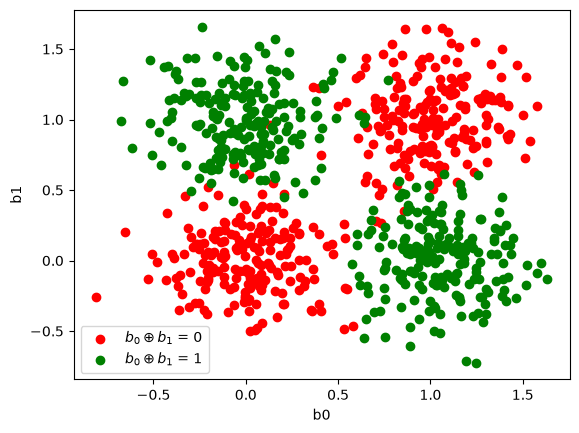

In [3]:
X, y = create_xor_dataset(num_samples_per_class=200, noise=0.25)

x0 = X[y == 0, :]
x1 = X[y == 1, :]

print(X.shape, y.shape)

plt.figure()
plt.scatter(x0[:, 0], x0[:, 1], c="red",label=r"$b_0 \oplus b_1$ = 0")
plt.scatter(x1[:, 0], x1[:, 1], c="green", label=r"$b_0 \oplus b_1$ = 1")
plt.xlabel("b0")
plt.ylabel("b1")
plt.legend()

### Slit into training and test sets

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=33)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(np.unique(y_train, return_counts=True))
print(np.unique(y_test, return_counts=True))

(640, 2) (160, 2) (640,) (160,)
(array([0., 1.]), array([313, 327]))
(array([0., 1.]), array([87, 73]))


### **Datasets & Dataloaders**

<div style="text-align: center;">
  <img src="imgs/ds_dl.png" alt="description" width="1200"/>
</div>

In PyTorch, `datasets` and `dataloaders` are integral components for efficiently managing and loading data during the training and evaluation of machine learning models. A dataset in PyTorch is essentially a container for your data, and a dataloader is responsible for efficiently iterating over the dataset in batches during training.

In [5]:
from torch.utils.data import TensorDataset, Dataset, DataLoader

train_dataset = TensorDataset(
    torch.FloatTensor(X_train), 
    torch.LongTensor(y_train)
)
test_dataset = TensorDataset(
    torch.FloatTensor(X_test), 
    torch.LongTensor(y_test)
)

print("Train/Test elements: ", len(train_dataset), len(test_dataset))

Train/Test elements:  640 160


In [6]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)  # shuffle=True -> randomizes the ordering of elements after each epoch
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

for i, batch in enumerate(test_loader):
    xi, yi = batch
    print(f"Batch {i}: ", xi.shape, yi.shape)

Batch 0:  torch.Size([64, 2]) torch.Size([64])
Batch 1:  torch.Size([64, 2]) torch.Size([64])
Batch 2:  torch.Size([32, 2]) torch.Size([32])


Custom datasets in PyTorch offer the flexibility to handle diverse data formats, apply specific data manipulations, and seamlessly integrate domain-specific features.

In [7]:
class CustomDataset(Dataset):
    def __init__(self, features, labels, transform=None):
        self.features = torch.FloatTensor(features)
        self.labels = torch.LongTensor(labels)
        self.transform = transform

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        x = self.features[index] 
        y = self.labels[index]

        sample = (x, y)

        if self.transform:
            sample = self.transform(sample)

        return sample

In the above, the `CustomDataset` class is a subclass of `Dataset`, containing inputs `X` and outputs `y`. The `__getitem__` method in CustomDataset retrieves a sample, and the custom transformation is applied.

In [8]:
class CustomTransform:
    def __init__(self, coeff=-0.5, bias=1):
        self.coeff = coeff
        self.bias = bias

    def __call__(self, sample):
        x, y = sample
        
        x_ = x * self.coeff + self.bias
        y_ = nn.functional.one_hot(y, num_classes=2)

        return (x_, y_)

custom_test_dataset = CustomDataset(X_test, y_test, transform=CustomTransform())
custom_test_dataloader = DataLoader(custom_test_dataset, batch_size=batch_size, shuffle=True)

for i, batch in enumerate(custom_test_dataloader):
    xi, yi = batch
    print(f"Batch {i}: ", xi.shape, yi.shape)

Batch 0:  torch.Size([64, 2]) torch.Size([64, 2])
Batch 1:  torch.Size([64, 2]) torch.Size([64, 2])
Batch 2:  torch.Size([32, 2]) torch.Size([32, 2])


### **Defining a Neural Network**

In PyTorch, constructing models begins with defining a custom class that inherits from `nn.Module`. This class encapsulates the architecture by incorporating various layers, which can be either pre-defined PyTorch modules, like `nn.Linear`, or custom layers (see `CustomLinear` from `customs.py`). The `__init__` method of the class is used to initialize these layers, setting parameters such as input and output sizes. The core computation occurs in the `forward` method, where the forward pass through the network is specified, including the sequence of layers and any activation functions. 

In [9]:
from customs import CustomLinear

class FFN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, use_custom=False):
        super(FFN, self).__init__()

        if use_custom:
            linear_layer = lambda input_size, output_size: CustomLinear(input_size, output_size)
        else:
            linear_layer = lambda input_size, output_size: nn.Linear(input_size, output_size)

        self.fc1 = linear_layer(input_size, hidden_size)
        self.fc2 = linear_layer(hidden_size, hidden_size)
        self.fc3 = linear_layer(hidden_size, output_size)

    def forward(self, x):
        # x: tensor of shape (batch_size, number_of_features)
        h = self.fc1(x)
        h = self.fc2(h)
        y = self.fc3(h)

        return y

**Observation**: we'll not be using Softmax after the final layer! PyTorch's `torch.nn.CrossEntropyLoss()` expects **unnormalized output values**, i.e. logits.

### **Define Training/Test Step**

In [10]:
from tqdm import tqdm

def step(model, dataloader, optimizer, loss_fn, is_training=True, device='cuda'):
    # Set the model to training mode if it's a training step, otherwise to evaluation mode
    model.train() if is_training else model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, labels in tqdm(dataloader, position=0, leave=True):
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        if is_training:
            outputs = model(inputs)
        else:
            with torch.no_grad():
                outputs = model(inputs)

        loss = loss_fn(outputs, labels) 

        # Backward pass and update if it's a training step
        if is_training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        _, predicted = torch.max(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_samples += labels.size(0)

        # Cumulative loss for reporting
        total_loss += loss.item()

    # Calculate average loss and accuracy
    avg_loss = total_loss / len(dataloader)
    accuracy = correct_predictions / total_samples if total_samples > 0 else None

    return avg_loss, accuracy

### **Training Loop**

Set training configuration:

In [11]:
### Architecture-related hyperparams
input_size = 2
hidden_size = 32
output_size = 2
use_custom = False

### Training-related hyperparams
epochs = 30
learning_rate = 1e-3
print_frequency = 15

Define model, optimizer and loss:

In [ ]:
model = FFN(input_size, hidden_size, output_size, use_custom=use_custom)

optimizer = torch.optim.Adam(
    model.parameters(), 
    lr=learning_rate
)

loss = nn.CrossEntropyLoss()

We'll use the standard categorical-crossentropy loss for multi-class problems.

**Question**: What should you change in order to be able to use Binary-Crossentropy?

In [13]:
for e in range(1, epochs + 1):
    train_loss, train_acc = step(model, train_loader, optimizer, loss, device="cpu")

    if e % print_frequency == 0:
        with torch.no_grad():
            test_loss, test_acc = step(model, test_loader, optimizer, loss, is_training=False, device="cpu")
        print(f"Epoch {e}/{epochs}: train_loss={train_loss} train_acc={train_acc} test_loss={test_loss} test_acc={test_acc}")

100%|██████████| 3/3 [00:00<00:00, 806.65it/s]


Epoch 15/30: train_loss=0.6944656729698181 train_acc=0.465625 test_loss=0.695139467716217 test_acc=0.44375


100%|██████████| 3/3 [00:00<00:00, 2981.73it/s]

Epoch 30/30: train_loss=0.6933975398540497 train_acc=0.4703125 test_loss=0.696474293867747 test_acc=0.44375


### **Visualizing Decision Boundaries**

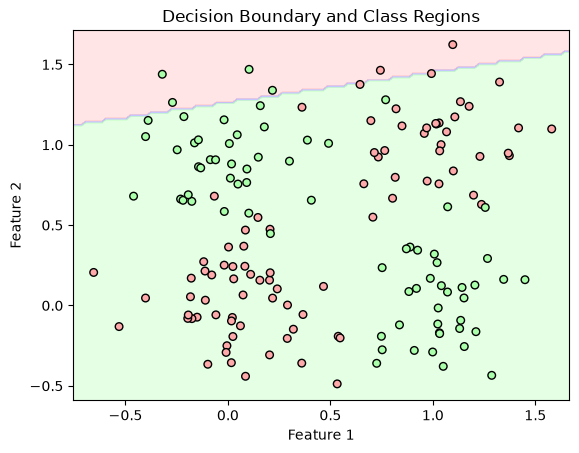

In [14]:
import utils
import importlib
importlib.reload(utils)
from utils import plot_decision_boundary

plot_decision_boundary(model, test_loader)

Why does this happen?

In [17]:
class FFN_non_linear(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, use_custom=False):
        super(FFN_non_linear, self).__init__()

        self.activation = nn.ReLU()
        
        if use_custom:
            linear_layer = lambda input_size, output_size: CustomLinear(input_size, output_size)
        else:
            linear_layer = lambda input_size, output_size: nn.Linear(input_size, output_size)

        self.fc1 = linear_layer(input_size, hidden_size)
        self.fc2 = linear_layer(hidden_size, hidden_size)
        self.fc3 = linear_layer(hidden_size, output_size)

    def forward(self, x):
        h = self.fc1(x)
        h = self.activation(h)
        h = self.fc2(h)
        h = self.activation(h)
        y = self.fc3(h)
        
        return y

In [18]:
model = FFN_non_linear(input_size, hidden_size, output_size, use_custom=use_custom)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss = nn.CrossEntropyLoss()

for e in range(1, epochs + 1):
    train_loss, train_acc = step(model, train_loader, optimizer, loss, device="cpu")

    if e % print_frequency == 0:
        test_loss, test_acc = step(model, test_loader, optimizer, loss, is_training=False, device="cpu")
        print(f"Epoch {e}/{epochs}: train_loss={train_loss} train_acc={train_acc} test_loss={test_loss} test_acc={test_acc}")

100%|██████████| 3/3 [00:00<00:00, 2583.76it/s]


Epoch 15/30: train_loss=0.28795818984508514 train_acc=0.9484375 test_loss=0.30154354870319366 test_acc=0.925


100%|██████████| 3/3 [00:00<00:00, 2242.54it/s]

Epoch 30/30: train_loss=0.11637591049075127 train_acc=0.959375 test_loss=0.1435698370138804 test_acc=0.925


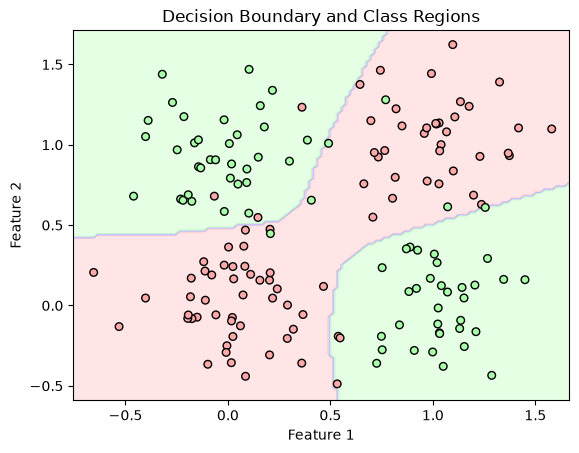

In [19]:
plot_decision_boundary(model, test_loader)

#### **Exercise: Play with the architecture**
Check, for different network depths and widths how the shape of the decision boundary changes, and draw some conclusions based on that. Look at how the decision boundary changes for the training data as well.

---
---


## 🛡️ **Application: Network Intrusion Detection (NSL-KDD)** <a class="anchor" id="nids"></a>

A **Network Intrusion Detection System (NIDS)** monitors network traffic and raises an alert when a connection looks malicious. Two classic families exist:

- **Direct Signature matching**: match traffic against known attack patterns. Precise, but blind to anything new.
- **ML-based**: learn from labelled traffic what "normal" and "attack" look like, and generalize to similar behaviour.

Here we treat the problem as a **supervised classification** task on tabular data, using exactly the tools built above: a fully-connected network, cross-entropy, Adam/SGD, `Dataset`/`DataLoader`, etc.

<div style="text-align: center;">
  <img src="imgs/nids.png" alt="description" width="1200"/>
</div>

### The dataset

**NSL-KDD** is a cleaned version of the KDD'99 benchmark (duplicate records removed, so a classifier cannot win by memorizing repeated rows). Each row is one network *connection*, described by 41 features, plus a label (`normal` or a specific attack name) and a "difficulty" score.

| Feature group | Examples | What it captures |
|---|---|---|
| **Basic** | `duration`, `protocol_type`, `service`, `flag`, `src_bytes`, `dst_bytes` | Properties of the connection itself |
| **Content** | `num_failed_logins`, `logged_in`, `root_shell`, `num_file_creations` | Payload-level behaviour (login attempts, privilege escalation) |
| **Time-based traffic** | `count`, `srv_count`, `serror_rate`, `same_srv_rate` | Statistics over the last 2 seconds |
| **Host-based traffic** | `dst_host_count`, `dst_host_serror_rate`, `dst_host_same_srv_rate` | Statistics over the last 100 connections to the same host |

Attack names are grouped in four categories:

| Category | Idea | Examples |
|---|---|---|
| **DoS** | Exhaust a resource to deny service | `neptune`, `smurf`, `back`, `teardrop` |
| **Probe** | Scan the network to find weaknesses | `satan`, `ipsweep`, `nmap`, `portsweep` |
| **R2L** (remote to local) | Remote attacker gains local access | `guess_passwd`, `warezclient`, `ftp_write` |
| **U2R** (user to root) | Normal user escalates privileges | `buffer_overflow`, `rootkit`, `loadmodule` |

We will use the two official files:
- `KDDTrain+.txt` — training set (~126k connections)
- `KDDTest+.txt` — test set (~22.5k connections)

> ⚠️ **The test set is deliberately *not* an i.i.d. sample of the training set**: it contains attack types that never appear in training. This mimics reality (new attacks keep appearing) and will be the main source of insight in this lab. Also keep in mind that NSL-KDD is derived from 1999 traffic, so it is a *teaching benchmark*, not a model of modern networks.

**Dataset download:** [Kaggle — NSL-KDD](https://www.kaggle.com/datasets/hassan06/nslkdd) (free account required). Place `KDDTrain+.txt` and `KDDTest+.txt` in `data/nslkdd/`.

**Alternative** - use the following `cURL` and `unzip` commands:

In [ ]:
!mkdir ./data # create data folder if it doesn't exist
!curl -L -o ./data/nslkdd.zip https://www.kaggle.com/api/v1/datasets/download/hassan06/nslkdd # download the dataset from Kaggle

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 13.8M  100 13.8M    0     0  6001k      0  0:00:02  0:00:02 --:--:-- 7551k


In [ ]:
!!unzip ./data/nslkdd.zip -d ./data/nslkdd # unzip the dataset into the data folder

['Archive:  ./data/nslkdd.zip',
 '  inflating: ./data/nslkdd/KDDTest+.arff  ',
 '  inflating: ./data/nslkdd/KDDTest+.txt  ',
 '  inflating: ./data/nslkdd/KDDTest-21.arff  ',
 '  inflating: ./data/nslkdd/KDDTest-21.txt  ',
 '  inflating: ./data/nslkdd/KDDTest1.jpg  ',
 '  inflating: ./data/nslkdd/KDDTrain+.arff  ',
 '  inflating: ./data/nslkdd/KDDTrain+.txt  ',
 '  inflating: ./data/nslkdd/KDDTrain+_20Percent.arff  ',
 '  inflating: ./data/nslkdd/KDDTrain+_20Percent.txt  ',
 '  inflating: ./data/nslkdd/KDDTrain1.jpg  ',
 '  inflating: ./data/nslkdd/index.html  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTest+.arff  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTest+.txt  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTest-21.arff  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTest-21.txt  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTest1.jpg  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTrain+.arff  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTrain+.txt  ',
 '  inflating: ./data/nslkdd/nsl-kdd/KDDTrai

### What you will do
1. Preprocess mixed (numeric + categorical) tabular data, with heavy-tailed features
2. Train an MLP and compare **optimizers** and learning rates
3. Measure the gap between *validation* and *test* performance, and understand where it comes from
4. **Visualize the latent space** learned by the network
5. Apply an **explainability** technique (permutation importance + Integrated Gradients) to see *what the network looks at*

### **Data & Preprocessing** <a class="anchor" id="nids_data"></a>

In [26]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 33
torch.manual_seed(SEED)
np.random.seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

DATA_DIR = "data/nslkdd"
TRAIN_FILE = os.path.join(DATA_DIR, "KDDTrain+.txt")
TEST_FILE = os.path.join(DATA_DIR, "KDDTest+.txt")

# Optional: download programmatically (needs `pip install kagglehub` and Kaggle credentials)
# import kagglehub
# print(kagglehub.dataset_download("hassan06/nslkdd"))   # then copy the .txt files into DATA_DIR

assert os.path.exists(TRAIN_FILE) and os.path.exists(TEST_FILE), \
    f"Download the dataset and put KDDTrain+.txt / KDDTest+.txt in {DATA_DIR}/"

Using device: cpu


The files have **no header**; each line has 41 features, the label, and a difficulty score:

In [28]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty",
]

train_df = pd.read_csv(TRAIN_FILE, header=None, names=COLUMNS)
test_df = pd.read_csv(TEST_FILE, header=None, names=COLUMNS)
train_df["label"] = train_df["label"].str.strip()
test_df["label"] = test_df["label"].str.strip()

print("Train:", train_df.shape, " Test:", test_df.shape)
train_df.head(10)

Train: (125973, 43)  Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21
5,0,tcp,private,REJ,0,0,0,0,0,0,...,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,neptune,21
6,0,tcp,private,S0,0,0,0,0,0,0,...,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
7,0,tcp,private,S0,0,0,0,0,0,0,...,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
8,0,tcp,remote_job,S0,0,0,0,0,0,0,...,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
9,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21


#### Labels

We build two targets: a **binary** one (`normal` = 0, `attack` = 1) that we will train on, and the attack **category**, which we keep for *analysis only* (to see which kinds of attacks the model finds hard).

In [29]:
ATTACK_CATEGORY = {
    "normal": "normal",
    # DoS
    **{a: "DoS" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop",
                          "apache2", "udpstorm", "processtable", "worm", "mailbomb"]},
    # Probe
    **{a: "Probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},
    # R2L
    **{a: "R2L" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster",
                          "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
                          "httptunnel", "sendmail", "named"]},
    # U2R
    **{a: "U2R" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]},
}

CATEGORIES = ["normal", "DoS", "Probe", "R2L", "U2R"]

for df in (train_df, test_df):
    df["category"] = df["label"].map(ATTACK_CATEGORY)
    assert df["category"].notna().all(), df.loc[df["category"].isna(), "label"].unique()
    df["is_attack"] = (df["category"] != "normal").astype(int)

summary = pd.DataFrame({
    "train": train_df["category"].value_counts(),
    "test": test_df["category"].value_counts(),
}).reindex(CATEGORIES)

summary["train (%)"] = 100 * summary["train"] / summary["train"].sum()
summary["test (%)"] = 100 * summary["test"] / summary["test"].sum()

print(summary.round(1))

unseen = sorted(set(test_df["label"]) - set(train_df["label"]))
print(f"\n{len(unseen)} attack types appear ONLY in the test set: {unseen}")
print("Fraction of test rows belonging to those unseen attacks: "
      f"{100 * test_df['label'].isin(unseen).mean():.1f}%")

          train  test  train (%)  test (%)
category                                  
normal    67343  9711       53.5      43.1
DoS       45927  7460       36.5      33.1
Probe     11656  2421        9.3      10.7
R2L         995  2885        0.8      12.8
U2R          52    67        0.0       0.3

17 attack types appear ONLY in the test set: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Fraction of test rows belonging to those unseen attacks: 16.6%


**Observations**
- In the binary view, the classes are roughly balanced, unlike in many real security datasets (where attacks are rare). So we will *not* need a `WeightedRandomSampler` here.
- In the 5-category view, however, **R2L** and especially **U2R** are very rare in training. Keep an eye on them.
- Some attack types in the test set were never seen during training.

#### Features

Three issues need care before feeding this to an MLP:

1. **Categorical features** (`protocol_type`, `service`, `flag`) → one-hot encoding. The set of columns must be defined from the **training** data only; a service present only in the test set simply gets all zeros.
2. **Heavy-tailed numeric features** (`src_bytes` ranges from 0 to ~10⁹). Standardizing raw values would squash almost every sample to ≈ 0 and let a few outliers dominate. A `log(1 + x)` transform comes first.
3. **Constant columns** (e.g. `num_outbound_cmds` is always 0) carry no information → drop.

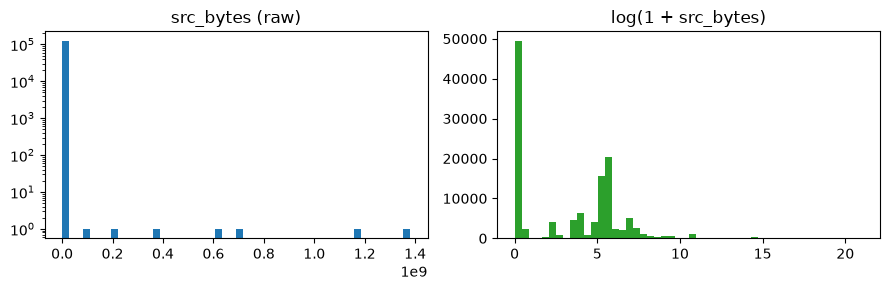

In [30]:
CAT_COLS = ["protocol_type", "service", "flag"]
LOG_COLS = ["duration", "src_bytes", "dst_bytes", "hot", "num_compromised", "num_root", "num_file_creations"]
NON_FEATURES = ["label", "difficulty", "category", "is_attack"]

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(train_df["src_bytes"], bins=50, color="tab:blue"); ax[0].set_title("src_bytes (raw)"); ax[0].set_yscale("log")
ax[1].hist(np.log1p(train_df["src_bytes"]), bins=50, color="tab:green"); ax[1].set_title("log(1 + src_bytes)")
plt.tight_layout(); plt.show()

In [50]:
def raw_features(df):
    X = df.drop(columns=NON_FEATURES).copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    return X

Xtr_raw, Xte_raw = raw_features(train_df), raw_features(test_df)

# One-hot columns are defined on the TRAIN set only; the test set is re-indexed to match.
Xtr_all = pd.get_dummies(Xtr_raw, columns=CAT_COLS, dtype=np.float32)
Xte_all = pd.get_dummies(Xte_raw, columns=CAT_COLS, dtype=np.float32).reindex(columns=Xtr_all.columns, fill_value=0.0)

# Drop constant columns (decided on the train set)
const_cols = [c for c in Xtr_all.columns if Xtr_all[c].nunique() == 1]
print("Constant columns dropped:", const_cols)
Xtr_all, Xte_all = Xtr_all.drop(columns=const_cols), Xte_all.drop(columns=const_cols)

feature_names = list(Xtr_all.columns)
print("Number of input features:", len(feature_names))

Xtr_all.head(10)

Constant columns dropped: ['num_outbound_cmds']
Number of input features: 121


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.0,6.198479,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,4.990433,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,5.451038,9.006264,0,0,0,0.0,0,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,5.298317,6.042633,0,0,0,0.0,0,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.000000,0.000000,0,0,0,0.0,0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


#### Train-val-test Split

- **train / validation**: a stratified 80/20 split of `KDDTrain+` (used for training and model selection).
- **test**: the official `KDDTest+` (used *only* for the final evaluation).

Standardization statistics are computed on the **train split only** (avoiding leakage, as before). We only scale the numeric columns, since one-hot columns for rare categories would otherwise get enormous standardized values at test time.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_tr, idx_val = train_test_split(
    np.arange(len(train_df)), test_size=0.2, random_state=SEED, stratify=train_df["category"]
)

num_cols = [c for c in feature_names if not any(c.startswith(cc + "_") for cc in CAT_COLS)]
num_idx = [feature_names.index(c) for c in num_cols]

scaler = StandardScaler().fit(Xtr_all.iloc[idx_tr][num_cols])

def to_tensor(df):
    arr = df.values.astype(np.float32)
    arr[:, num_idx] = scaler.transform(df[num_cols]).astype(np.float32)
    return torch.tensor(arr)

X_tr, X_val, X_te = to_tensor(Xtr_all.iloc[idx_tr]), to_tensor(Xtr_all.iloc[idx_val]), to_tensor(Xte_all)
y_tr = torch.tensor(train_df["is_attack"].values[idx_tr])
y_val = torch.tensor(train_df["is_attack"].values[idx_val])
y_te = torch.tensor(test_df["is_attack"].values)

df_val = train_df.iloc[idx_val].reset_index(drop=True)   # keep metadata for per-category analysis
df_te = test_df.reset_index(drop=True)

print(f"train {tuple(X_tr.shape)}  val {tuple(X_val.shape)}  test {tuple(X_te.shape)}")

BATCH_SIZE = 256
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)

train (100778, 121)  val (25195, 121)  test (22544, 121)


### **Model & Training** <a class="anchor" id="nids_train"></a>

We use the same building blocks as before: `Linear` layers with non-linear activations, but now with two commonly used additions:

- **Batch Normalization**: normalizes each hidden layer's activations over the batch; typically makes training faster and less sensitive to the learning rate.
- **Dropout**: randomly zeroes activations during training (a regularizer).

Both behave differently in `train()` and `eval()` mode, hence the `model.train()` / `model.eval()` calls.

The network is split in a `features` part (everything up to the last hidden layer) and a linear `classifier`. This exposes the **latent representation** through `embed`, which we will visualize later.

In [47]:
class IDSNet(nn.Module):
    def __init__(self, input_size, hidden_sizes=(128, 64, 32), output_size=2, dropout=0.1):
        super().__init__()
        layers, in_size = [], input_size
        
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            in_size = h
        
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(in_size, output_size)   # outputs logits (no softmax: see CrossEntropyLoss)

    def embed(self, x):
        return self.features(x)

    def forward(self, x):
        return self.classifier(self.features(x))

model = IDSNet(X_tr.shape[1])

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

IDSNet(
  (features): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.1, inplace=False)
  )
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)
Trainable parameters: 26466


#### Training & validation

`train_with_validation` uses a similar loop as `step` from the XOR section (forward → loss → backward → update), extended to log validation metrics at the end of each epoch and optionally restore the best-validation weights. `predict` runs inference in batches, with gradients disabled.

In [34]:
@torch.no_grad() # this ensures we are not computing gradients
def predict(model, X, batch_size=4096):
    """Returns logits (on CPU) for all rows of X."""
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(device)).cpu() for i in range(0, len(X), batch_size)])

def train_with_validation(model, loader, optimizer, epochs, val=None, keep_best=False, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    model.to(device)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_loss, best_state = float("inf"), None

    for e in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)
        hist["train_loss"].append(total / n)

        if val is not None:
            logits = predict(model, val[0])
            vl = loss_fn(logits, val[1]).item()
            va = (logits.argmax(1) == val[1]).float().mean().item()
            
            hist["val_loss"].append(vl)
            hist["val_acc"].append(va)
            
            if keep_best and vl < best_loss:
                best_loss, best_state = vl, copy.deepcopy(model.state_dict())
            if verbose and (e == 1 or e % 5 == 0 or e == epochs):
                print(f"Epoch {e:3d}/{epochs}: train_loss={hist['train_loss'][-1]:.4f} "
                      f"val_loss={vl:.4f} val_acc={va:.4f}")

    if keep_best and best_state is not None:
        model.load_state_dict(best_state)
    return hist

Epoch   1/8: train_loss=0.1656 val_loss=0.0653 val_acc=0.9827
Epoch   5/8: train_loss=0.0353 val_loss=0.0255 val_acc=0.9927
Epoch   8/8: train_loss=0.0271 val_loss=0.0192 val_acc=0.9940
SGD (lr=1e-2)              final val_loss=0.0192  val_acc=0.9940
Epoch   1/8: train_loss=0.0630 val_loss=0.0234 val_acc=0.9925
Epoch   5/8: train_loss=0.0152 val_loss=0.0129 val_acc=0.9965
Epoch   8/8: train_loss=0.0121 val_loss=0.0087 val_acc=0.9976
SGD+momentum (lr=1e-2)     final val_loss=0.0087  val_acc=0.9976
Epoch   1/8: train_loss=0.0368 val_loss=0.0189 val_acc=0.9927
Epoch   5/8: train_loss=0.0128 val_loss=0.0135 val_acc=0.9956
Epoch   8/8: train_loss=0.0102 val_loss=0.0081 val_acc=0.9980
Adam (lr=1e-2)             final val_loss=0.0081  val_acc=0.9980


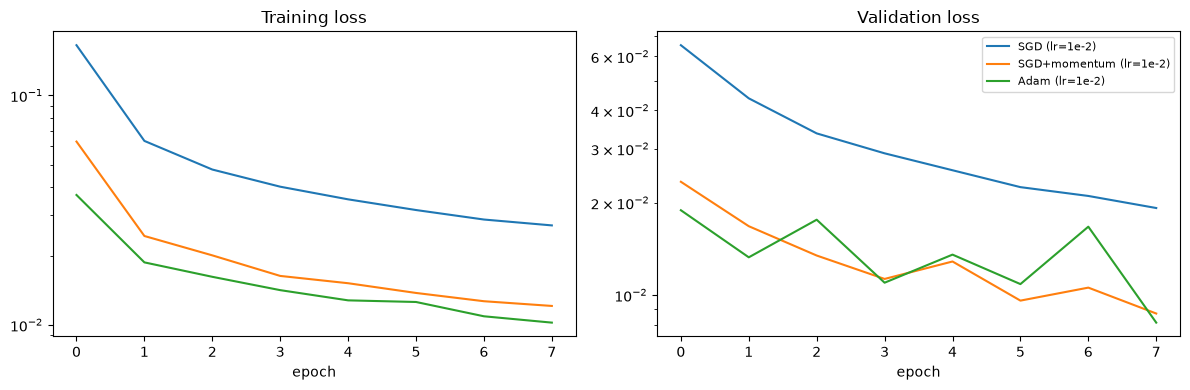

In [54]:
optimizer_configs = {
    "SGD (lr=1e-2)":            lambda p: torch.optim.SGD(p, lr=1e-2),
    "SGD+momentum (lr=1e-2)":   lambda p: torch.optim.SGD(p, lr=1e-2, momentum=0.9),
    "Adam (lr=1e-2)":           lambda p: torch.optim.Adam(p, lr=1e-2),
}

EPOCHS_OPT = 8
histories = {}
models = {}
for name, make_opt in optimizer_configs.items():
    torch.manual_seed(SEED)                       # same init & same batch order for every optimizer
    m = IDSNet(X_tr.shape[1])
    histories[name] = train_with_validation(m, train_loader, make_opt(m.parameters()), EPOCHS_OPT, val=(X_val, y_val), verbose=True)
    models[name] = m

    print(f"{name:26s} final val_loss={histories[name]['val_loss'][-1]:.4f}  val_acc={histories[name]['val_acc'][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h["train_loss"], label=name)
    ax[1].plot(h["val_loss"], label=name)
ax[0].set_title("Training loss")
ax[1].set_title("Validation loss")
for a in ax: 
    a.set_xlabel("epoch")
    a.set_yscale("log")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [56]:
# final model selection: pick the one with the best validation loss
model = models["Adam (lr=1e-2)"]

### **Evaluation under Distribution Shift** <a class="anchor" id="nids_eval"></a>

In intrusion detection, accuracy alone is misleading. The two kinds of errors have very different costs:

- **False negative** (attack classified as normal): an intrusion goes unnoticed. Typically the costly one.
- **False positive** (normal classified as attack): a false alarm; too many of them and analysts start ignoring the system.

So we look at **precision**, **recall** (a.k.a. *detection rate*) and **F1** on the attack class, the confusion matrix, and the detection rate **per attack category**.

In [57]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def evaluate(model, X, y, df, name):
    pred = predict(model, X).argmax(1).numpy()
    y_np = y.numpy()
    print(f"===== {name} =====")
    print(classification_report(y_np, pred, target_names=["normal", "attack"], digits=3))

    rows = []
    for cat in CATEGORIES:
        m = (df["category"] == cat).values
        if m.sum() == 0:
            continue
        # for 'normal' this is the specificity (normal kept as normal); for attacks it is the detection rate
        rows.append({"category": cat, "n": int(m.sum()),
                     "correctly classified (%)": 100 * (pred[m] == y_np[m]).mean()})
    print(pd.DataFrame(rows).set_index("category").round(1))
    return pred

pred_val = evaluate(model, X_val, y_val, df_val, "Validation (held-out part of KDDTrain+)")
print()
pred_te = evaluate(model, X_te, y_te, df_te, "Test (KDDTest+)")

===== Validation (held-out part of KDDTrain+) =====
              precision    recall  f1-score   support

      normal      0.997     0.999     0.998     13469
      attack      0.999     0.997     0.998     11726

    accuracy                          0.998     25195
   macro avg      0.998     0.998     0.998     25195
weighted avg      0.998     0.998     0.998     25195

              n  correctly classified (%)
category                                 
normal    13469                      99.9
DoS        9186                     100.0
Probe      2331                      99.7
R2L         199                      89.4
U2R          10                      50.0

===== Test (KDDTest+) =====
              precision    recall  f1-score   support

      normal      0.706     0.966     0.816      9711
      attack      0.964     0.696     0.808     12833

    accuracy                          0.812     22544
   macro avg      0.835     0.831     0.812     22544
weighted avg      0.853   

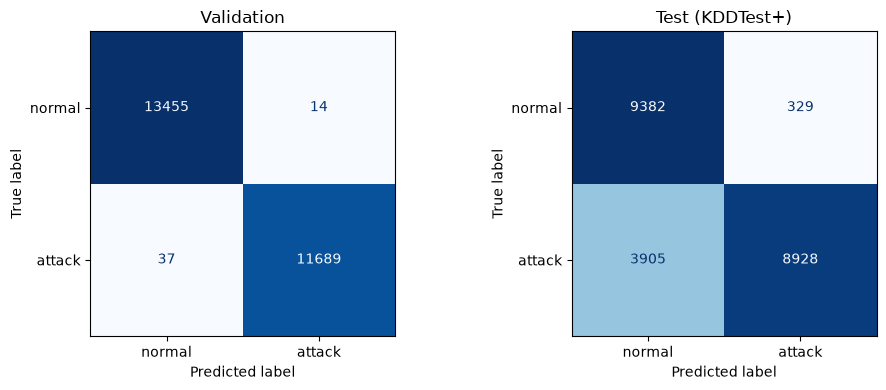

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_val.numpy(), pred_val, display_labels=["normal", "attack"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Validation")
ConfusionMatrixDisplay.from_predictions(y_te.numpy(), pred_te, display_labels=["normal", "attack"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Test (KDDTest+)")
plt.tight_layout(); plt.show()

#### Seen vs. unseen attack types

Let's check whether the test errors concentrate on attacks the model never saw during training:

In [59]:
is_unseen = df_te["label"].isin(unseen).values
atk = df_te["is_attack"].values == 1

det_seen = (pred_te[atk & ~is_unseen] == 1).mean()
det_unseen = (pred_te[atk & is_unseen] == 1).mean()
print(f"Detection rate on attacks SEEN in training   : {100 * det_seen:.1f}%  (n={int((atk & ~is_unseen).sum())})")
print(f"Detection rate on attacks UNSEEN in training : {100 * det_unseen:.1f}%  (n={int((atk & is_unseen).sum())})")

per_attack = (df_te[atk].assign(detected=pred_te[atk] == 1)
              .groupby("label")["detected"].agg(["mean", "size"]).sort_values("mean"))
per_attack["mean"] *= 100
per_attack.columns = ["detected (%)", "n"]
per_attack["seen in train"] = [l not in unseen for l in per_attack.index]
print("\nWorst 10 attack types on the test set:")
print(per_attack.head(10).round(1))

Detection rate on attacks SEEN in training   : 78.8%  (n=9083)
Detection rate on attacks UNSEEN in training : 47.3%  (n=3750)

Worst 10 attack types on the test set:
               detected (%)    n  seen in train
label                                          
sqlattack               0.0    2          False
sendmail                0.0   14          False
xsnoop                  0.0    4          False
phf                     0.0    2           True
snmpgetattack           0.0  178          False
multihop                0.0   18           True
mailbomb                0.0  293          False
land                    0.0    7           True
rootkit                 0.0   13           True
imap                    0.0    1           True


**Discussion**
- The validation accuracy is typically very high, while the test accuracy is considerably lower. **Same model, same features, only the data differ.** Why? (Hint: validation comes from the same distribution as training: the *same attack types* with near-identical behaviour; the test set contains new ones.)
- A random split of the training file therefore **overestimates** real-world performance. Which evaluation protocol better reflects deployment?
- Which categories suffer most? Compare with the category frequencies in the training set printed earlier.
- A lower decision threshold on $P(\text{attack})$ trades false negatives for false positives. For an IDS, which side would you lean on, and who pays the cost?

### **Latent Space Visualization** <a class="anchor" id="nids_latent"></a>

The last hidden layer maps each connection to a 32-dimensional vector, the **latent representation** on which the final linear layer makes its decision. Since the classifier is *linear* in this space, the network is effectively learning a representation in which attacks and normal traffic become (almost) linearly separable.

We project this space to 2D with **t-SNE** (a non-linear method that preserves local neighbourhoods) and compare it with t-SNE applied to the **raw input features**. Points are colored by attack category (which the network never saw as a target!).

> t-SNE plots are for *qualitative* intuition. Distances between far-apart clusters and cluster sizes are not meaningful.

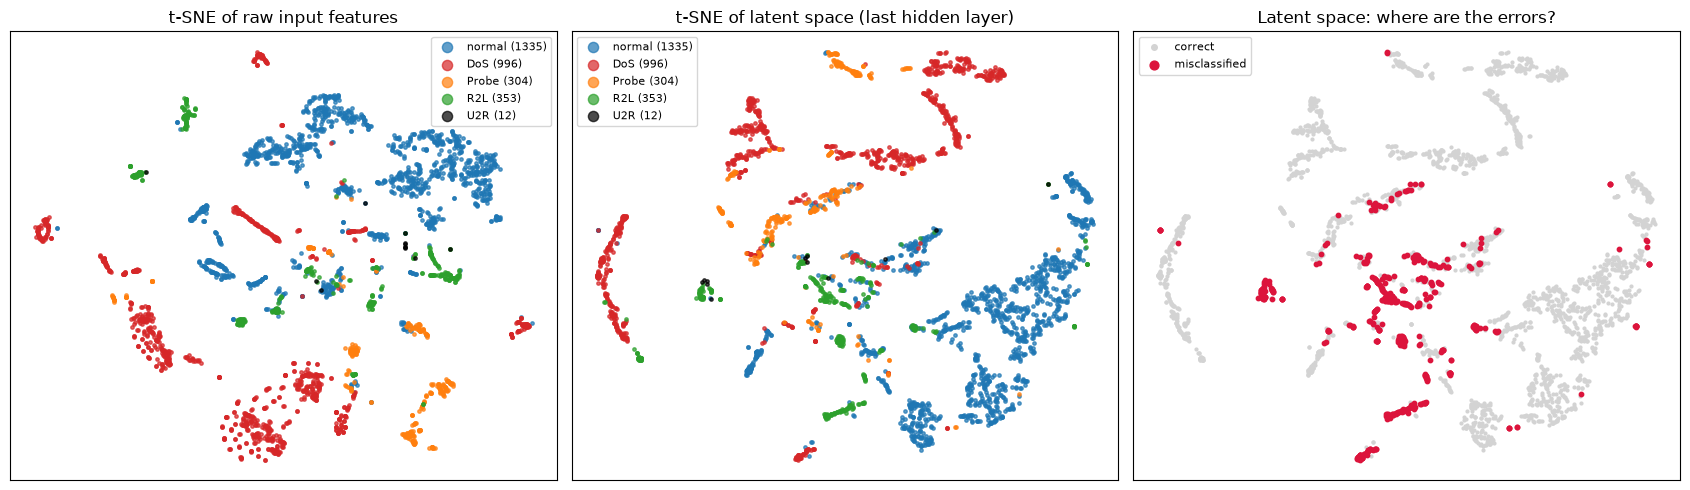

In [43]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(SEED)
sub = rng.choice(len(X_te), size=min(3000, len(X_te)), replace=False)
Xs, cats, correct = X_te[sub], df_te["category"].values[sub], (pred_te[sub] == y_te.numpy()[sub])

model.eval()
with torch.no_grad():
    Z = model.embed(Xs.to(device)).cpu().numpy()          # (n, 32) latent vectors

tsne = lambda A: TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(A)
emb_raw, emb_lat = tsne(Xs.numpy()), tsne(Z)

palette = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "black"}

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, emb, title in [(ax[0], emb_raw, "t-SNE of raw input features"),
                      (ax[1], emb_lat, "t-SNE of latent space (last hidden layer)")]:
    for c in CATEGORIES:
        m = cats == c
        a.scatter(emb[m, 0], emb[m, 1], s=6, c=palette[c], label=f"{c} ({m.sum()})", alpha=0.7)
    a.set_title(title); a.legend(markerscale=3, fontsize=8)

ax[2].scatter(emb_lat[correct, 0], emb_lat[correct, 1], s=4, c="lightgray", label="correct")
ax[2].scatter(emb_lat[~correct, 0], emb_lat[~correct, 1], s=10, c="crimson", label="misclassified")
ax[2].set_title("Latent space: where are the errors?"); ax[2].legend(markerscale=2, fontsize=8)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Questions**
- Are the DoS / Probe / normal groups better separated in the latent space than in the raw input space?
- Where do the **misclassified** points lie, in the middle of a cluster or between clusters? Which categories do they belong to?
- Do R2L / U2R points form their own cluster, or do they sit *inside* the normal cluster? What does this say about why they are hard to detect?
- *Try it*: color the points by **protocol_type** or by *seen/unseen* attack type instead.

### **Explainability** <a class="anchor" id="nids_xai"></a>

A security analyst who gets an alert will ask: *"why was this flagged?"*, and a model developer will ask: *"is the model relying on sensible signals?"*. We look at two complementary techniques:

| | **Permutation importance** | **xAI techniques** |
|---|---|---|
| Scope | **Global** (the whole test set) | **Local** (one connection) |
| Idea | Shuffle one feature across samples, which breaks its link with the label; measure the performance drop | Accumulate gradients along a straight path from a *baseline* to the input |
| Needs gradients? | No (model-agnostic) | Yes |

A note on the one-hot encoded features: `service_http` and `service_ftp` are not meaningful on their own, so we **group** all one-hot columns back to their original feature (`service`) and treat each group as one unit.

In [60]:
# Map every input column to its original feature (one-hot columns -> their parent categorical feature)
def group_of(col):
    for cc in CAT_COLS:
        if col.startswith(cc + "_"):
            return cc
    return col

groups = {}
for j, c in enumerate(feature_names):
    groups.setdefault(group_of(c), []).append(j)

print(f"{len(feature_names)} input columns -> {len(groups)} original features")
print(groups)

121 input columns -> 40 original features
{'duration': [0], 'src_bytes': [1], 'dst_bytes': [2], 'land': [3], 'wrong_fragment': [4], 'urgent': [5], 'hot': [6], 'num_failed_logins': [7], 'logged_in': [8], 'num_compromised': [9], 'root_shell': [10], 'su_attempted': [11], 'num_root': [12], 'num_file_creations': [13], 'num_shells': [14], 'num_access_files': [15], 'is_host_login': [16], 'is_guest_login': [17], 'count': [18], 'srv_count': [19], 'serror_rate': [20], 'srv_serror_rate': [21], 'rerror_rate': [22], 'srv_rerror_rate': [23], 'same_srv_rate': [24], 'diff_srv_rate': [25], 'srv_diff_host_rate': [26], 'dst_host_count': [27], 'dst_host_srv_count': [28], 'dst_host_same_srv_rate': [29], 'dst_host_diff_srv_rate': [30], 'dst_host_same_src_port_rate': [31], 'dst_host_srv_diff_host_rate': [32], 'dst_host_serror_rate': [33], 'dst_host_srv_serror_rate': [34], 'dst_host_rerror_rate': [35], 'dst_host_srv_rerror_rate': [36], 'protocol_type': [37, 38, 39], 'service': [40, 41, 42, 43, 44, 45, 46, 47,

#### Global: permutation importance

For each feature group we shuffle its values **jointly** across test samples (the same permutation for all columns of a group, so one-hot encodings stay valid) and record the drop in accuracy, averaged over a few repetitions.

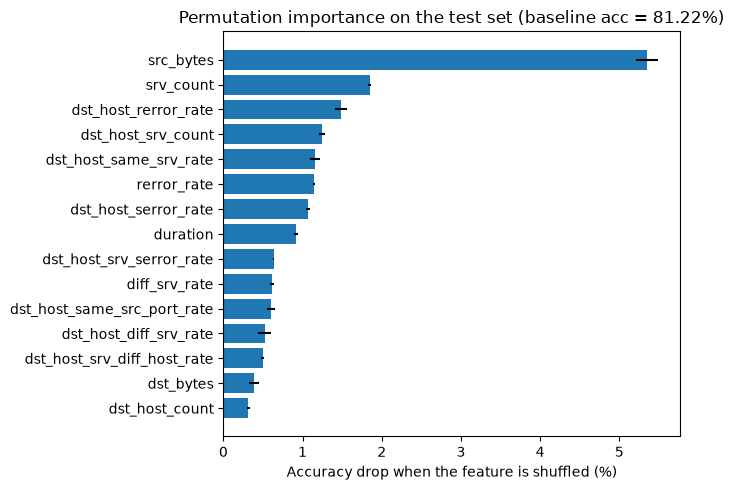

In [64]:
@torch.no_grad()
def permutation_importance(model, X, y, groups, n_repeats=3, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    base = (predict(model, X).argmax(1) == y).float().mean().item() * 100
    imp = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.clone()
            perm = torch.randperm(len(X), generator=g)
            Xp[:, cols] = X[perm][:, cols]
            drops.append(base - (predict(model, Xp).argmax(1) == y).float().mean().item() * 100)
        imp[name] = (np.mean(drops), np.std(drops))
    return base, imp

base_acc, imp = permutation_importance(model, X_te, y_te, groups)
imp_df = pd.DataFrame(imp, index=["drop", "std"]).T.sort_values("drop", ascending=False)

top = imp_df.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top["drop"], xerr=top["std"], color="tab:blue")
plt.xlabel("Accuracy drop when the feature is shuffled (%)")
plt.title(f"Permutation importance on the test set (baseline acc = {base_acc:.2f}%)")
plt.tight_layout(); plt.show()

- **`src_bytes`**: bytes sent from the source to the destination in the connection. Attacks often have a characteristic payload size (e.g. SYN floods send 0 bytes), unlike varied normal traffic.
- **`srv_count`**: number of connections to the same service in the last 2 seconds. Floods and scans produce bursts towards one service.
- **`dst_host_rerror_rate`**: fraction of the last 100 connections to the same host that were rejected. High during port scans, which probe closed ports.

**Questions**
- Do the top features match your intuition of what separates attacks from normal traffic? (e.g. a SYN flood such as `neptune` produces many half-open connections; the `serror_rate` features count exactly that.)
- Permutation importance computed on the *test* set reflects the model's reliance in the shifted setting; compute it on the validation set too. Do the rankings agree?

---

## 📓 Homework (20 pts, teams of 2): Robust Multi-class Intrusion Detection under Distribution Shift <a class="anchor" id="hw"></a>

In the lab you saw that an MLP can be excellent on a validation split and much worse on `KDDTest+`, especially on rare categories (R2L, U2R) and on attacks absent from the training set. In this homework you will **diagnose** and **mitigate** this behaviour.

Steps:
1. **Problem Formulation** `(5 pts)`
   - Multi-class (5 categories) classifier on NSL-KDD: model definition, pre-processing, training and evaluation setup.
   - Clearly report a **baseline**: per-class precision/recall/F1 and the confusion matrix, on validation **and** test.
2. **Failure Diagnosis** `(7.5 pts)`
   - Define precisely what "failure" means in your case (e.g. low recall on specific categories, accuracy gap between validation and test, missed unseen attacks) `(2.5 pts)`.
   - Use **at least 2 diagnostic methods** `(2 x 2.5 pts)`. Examples: per-class / per-attack-type analysis, latent-space visualization, permutation importance or any other explainable technique, comparing the train and test feature distributions.
3. **Mitigation** `(7.5 pts)`
   - Implement **at least 2 methods** aimed at improving the failure you identified `(2 x 2.5 pts)`, and measure their effectiveness against the baseline. Examples: class-weighted loss or `WeightedRandomSampler`, focal loss, removing brittle features, stronger regularization / early stopping on a *shifted* validation set (e.g. hold out entire attack types), data augmentation (noise), ensembling.

No project report is required. Your submission will consist of:
1. A `.zip` or a public GitHub repository containing the source code. You can include all your homework in a single Jupyter notebook, provided you list any necessary dependencies.
2. A `5-minute` presentation in `.pdf` format, which will be presented in the last week of this course. The presentation should be made similar to [this Overleaf template](https://www.overleaf.com/latex/templates/uchicago-beamer/gpcrpvqzvdfr), and should include:
   - A brief description of the task: objective, dataset, model, training setup
   - Your failure-diagnosis methodology and findings
   - Your mitigation methodology
   - Mitigation results and limitations
3. ⚠️ **Presentation is mandatory:** a homework submitted without being presented presentation will **not be scored**.